<a href="https://colab.research.google.com/github/diolenomatias-ops/neurostartup/blob/main/NeuroStartup_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 NeuroStartup — RetémJá: prevendo quem vai cancelar

**Atividade Prática 4 · IA e Machine Learning · Prof. Hercules Ramos**
**Desafio escolhido:** 2 · Prever cancelamento de clientes (churn) — inspiração: Vivo, Claro, streaming

**Integrantes:**


*Bruna Karlla Fernandes Marques - 2025115639*


*Dioleno Matias dos Santos - 2893378*


*Janaina Maria Abreu da Silva - 2780529*



> **O problema do "cliente":** uma operadora de telefonia/internet perde cerca de 1 em cada 4 clientes. Conquistar um cliente novo custa bem mais caro que manter um antigo. O time de retenção quer uma lista, toda semana, de **quem tem mais risco de cancelar**, para ligar antes e oferecer algo.
>
> **O que a rede prevê:** se o cliente vai cancelar (**sim/não**) → classificação binária.



## 0 · Ferramentas e semente

In [ ]:
# Se estiver no VS Code, rode uma vez no terminal:
# pip install numpy pandas matplotlib scikit-learn tensorflow ipywidgets joblib
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)
print("Keras", keras.__version__)

Keras 3.13.2


## 1 · Conhecer os dados

Base pública **Telco Customer Churn** (IBM), a mesma do Kaggle indicado no enunciado:
https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Para o notebook rodar sem login no Kaggle, baixamos o mesmo CSV direto do repositório público da IBM no GitHub.

In [ ]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
print("Linhas, colunas:", df.shape)
df.head(3).T

Linhas, colunas: (7043, 21)


,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


**⚠️ Cuidado do enunciado:** a coluna `TotalCharges` vem como texto e tem alguns valores vazios.
Olhando de perto, os vazios são todos de clientes com `tenure = 0` (acabaram de entrar, ainda não pagaram nada) → o valor certo é **0**.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
vazios = df[df["TotalCharges"].isna()]
print("Valores vazios em TotalCharges:", len(vazios), "| tenure desses clientes:", vazios["tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

df["cancelou"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])          # o ID não ensina nada; Churn virou 'cancelou'
print(f"Taxa de cancelamento: {df['cancelou'].mean():.1%}")

Valores vazios em TotalCharges: 11 | tenure desses clientes: [0]
Taxa de cancelamento: 26.5%


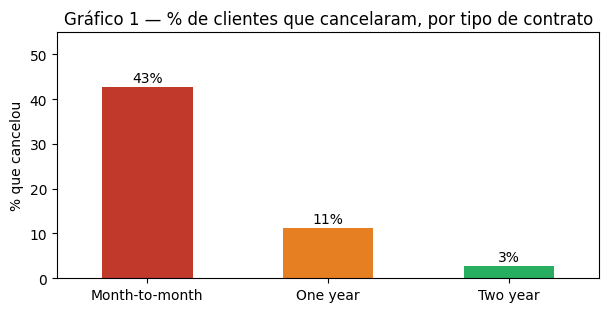

Conclusão: no contrato mês a mês, 43% cancelam; no de 2 anos, só 3%. O tipo de contrato é o sinal mais forte de risco.


In [ ]:
# Gráfico 1 — cancelamento por tipo de contrato
taxa_contrato = df.groupby("Contract")["cancelou"].mean().sort_values(ascending=False)
ax = (taxa_contrato * 100).plot(kind="bar", figsize=(7, 3.2), color=["#c0392b", "#e67e22", "#27ae60"],
                                title="Gráfico 1 — % de clientes que cancelaram, por tipo de contrato")
ax.set_ylabel("% que cancelou"); ax.set_xlabel(""); plt.xticks(rotation=0)
for i, v in enumerate(taxa_contrato * 100): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.ylim(0, 55); plt.show()
print(f"Conclusão: no contrato mês a mês, {taxa_contrato['Month-to-month']:.0%} cancelam; "
      f"no de 2 anos, só {taxa_contrato['Two year']:.0%}. O tipo de contrato é o sinal mais forte de risco.")

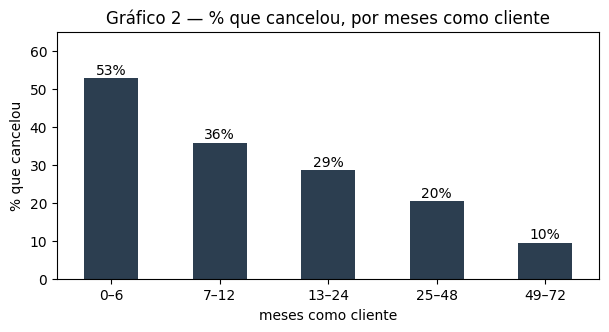

Conclusão: nos 6 primeiros meses, 53% cancelam; depois de 4 anos, só 10%. O começo da relação é o momento crítico para a retenção agir.


In [ ]:
# Gráfico 2 — cancelamento pelo tempo de casa (meses como cliente)
faixas = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
taxa_tempo = df.groupby(faixas, observed=True)["cancelou"].mean()
ax = (taxa_tempo * 100).plot(kind="bar", figsize=(7, 3.2), color="#2c3e50",
                             title="Gráfico 2 — % que cancelou, por meses como cliente")
ax.set_ylabel("% que cancelou"); ax.set_xlabel("meses como cliente"); plt.xticks(rotation=0)
for i, v in enumerate(taxa_tempo * 100): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.ylim(0, 65); plt.show()
print(f"Conclusão: nos 6 primeiros meses, {taxa_tempo.iloc[0]:.0%} cancelam; depois de 4 anos, só {taxa_tempo.iloc[-1]:.0%}. "
      "O começo da relação é o momento crítico para a retenção agir.")

### Transformando texto em números

A rede só entende números. Colunas **sim/não** viram 1/0; colunas com várias opções (tipo de contrato, forma de pagamento…) viram uma coluna 0/1 para cada opção (*one-hot*).
Guardamos isso numa função, porque **o produto (Passo 4) precisa preparar o cliente novo exatamente do mesmo jeito**.

In [ ]:
SIM_NAO = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
CATEGORICAS = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]

def preparar(dados, colunas=None):
    d = dados.copy()
    for c in SIM_NAO:
        d[c] = (d[c] == "Yes").astype(int)
    d["gender"] = (d["gender"] == "Female").astype(int)
    d = pd.get_dummies(d, columns=CATEGORICAS, dtype=int)
    if colunas is not None:                      # cliente novo: mesmas colunas, na mesma ordem
        d = d.reindex(columns=colunas, fill_value=0)
    return d.astype(float)

X_bruto, y = df.drop(columns=["cancelou"]), df["cancelou"].values
X = preparar(X_bruto)
COLUNAS = list(X.columns)
print("Colunas de entrada depois da preparação:", len(COLUNAS))

Colunas de entrada depois da preparação: 40


### 🔒 A regra do cofre

```
7.043 clientes
├── Teste (20%) ──────── 🔒 COFRE: só abre no final, uma única vez
└── Resto (80%)
    ├── Treino (60%) ─── a rede estuda aqui
    └── Validação (20%)  o "simulado" para escolher a melhor rede
```
Usamos `stratify` para as três partes terem a mesma proporção de cancelamentos (~27%).
O `StandardScaler` é ajustado **só no treino**; aplicar `fit` na validação ou no teste seria espiar a prova.

In [ ]:
X_resto, X_teste, y_resto, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)   # 🔒 cofre
X_treino, X_valid, y_treino, y_valid = train_test_split(X_resto, y_resto, test_size=0.25,
                                                        random_state=SEED, stratify=y_resto)
escala = StandardScaler().fit(X_treino)
X_treino_e, X_valid_e = escala.transform(X_treino), escala.transform(X_valid)
print("Treino:", X_treino.shape, "| Validação:", X_valid.shape, "| Teste (cofre):", X_teste.shape)

Treino: (4225, 40) | Validação: (1409, 40) | Teste (cofre): (1409, 40)


## 2 · Baseline × rede

**Como medir se está bom?** Só 27% cancelam: um "modelo" que diz sempre *"ninguém vai cancelar"* já acerta 73% sem fazer nada.
Por isso a acurácia sozinha engana. Olhamos três números:

| Métrica | Em português |
|---|---|
| **AUC** (critério de escolha) | Pegando um cliente que cancela e um que fica, a chance de o modelo dar nota de risco maior para quem cancela. 50% = chute, 100% = perfeito |
| **Recall** | De cada 100 clientes que vão cancelar, quantos o modelo pega |
| **Acurácia** | % de acertos no geral (só para referência) |

In [ ]:
def medir(y_real, prob, corte=0.5):
    pred = (prob >= corte).astype(int)
    return {"auc": round(roc_auc_score(y_real, prob), 4),
            "recall": round(recall_score(y_real, pred), 4),
            "precisao": round(precision_score(y_real, pred, zero_division=0), 4),
            "acuracia": round(accuracy_score(y_real, pred), 4)}

registros = []

# Baseline 0 — o "preguiçoso": ninguém cancela
registros.append({"modelo": "Preguiçoso (ninguém cancela)", "arquitetura": "-", "epocas": "-",
                  **medir(y_valid, np.zeros(len(y_valid)))})

# Baseline 1 — modelo simples: regressão logística (Aula 05)
logistica = LogisticRegression(max_iter=2000).fit(X_treino_e, y_treino)
registros.append({"modelo": "Regressão logística (baseline)", "arquitetura": "-", "epocas": "-",
                  **medir(y_valid, logistica.predict_proba(X_valid_e)[:, 1])})

# Bônus — árvore de decisão
arvore = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(X_treino_e, y_treino)
registros.append({"modelo": "Árvore de decisão (bônus)", "arquitetura": "max_depth=5", "epocas": "-",
                  **medir(y_valid, arvore.predict_proba(X_valid_e)[:, 1])})

pd.DataFrame(registros)

,modelo,arquitetura,epocas,auc,recall,precisao,acuracia
0,Preguiçoso (ninguém cancela),-,-,0.5000,0.0000,0.0000,0.7346
1,Regressão logística (baseline),-,-,0.8362,0.5401,0.6601,0.8041
2,Árvore de decisão (bônus),max_depth=5,-,0.8236,0.4278,0.6426,0.7850


### Testando redes em Keras (4 arquiteturas)

Problema **sim/não** → última camada `Dense(1, activation="sigmoid")` e `loss="binary_crossentropy"` (tabela "Qual saída usar?").
Todas com **Dropout** (jogadores faltando) e **Early Stopping** (parar no melhor simulado e guardar a melhor versão).

In [ ]:
ARQUITETURAS = {"rede_16": [16], "rede_32": [32], "rede_64_32": [64, 32], "rede_128_64": [128, 64]}
redes, historicos = {}, {}

for nome, camadas in ARQUITETURAS.items():
    keras.utils.set_random_seed(SEED)
    rede = keras.Sequential([keras.Input(shape=(X_treino_e.shape[1],))])
    for n in camadas:
        rede.add(layers.Dense(n, activation="relu"))
        rede.add(layers.Dropout(0.3))
    rede.add(layers.Dense(1, activation="sigmoid"))
    rede.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    parada = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    hist = rede.fit(X_treino_e, y_treino, validation_data=(X_valid_e, y_valid),
                    epochs=200, batch_size=32, verbose=0, callbacks=[parada])
    redes[nome], historicos[nome] = rede, hist
    prob_val = rede.predict(X_valid_e, verbose=0).ravel()
    registros.append({"modelo": f"Keras {nome}", "arquitetura": str(camadas) + " + dropout 0.3",
                      "epocas": len(hist.history["loss"]), **medir(y_valid, prob_val)})
    print(f"{nome:12s} parou na época {len(hist.history['loss']):3d} | parâmetros: {rede.count_params():5d}")

experimentos = pd.DataFrame(registros)
experimentos.to_csv("experimentos.csv", index=False)
experimentos

rede_16      parou na época  20 | parâmetros:   673
rede_32      parou na época  31 | parâmetros:  1345
rede_64_32   parou na época  18 | parâmetros:  4737
rede_128_64  parou na época  12 | parâmetros: 13569


,modelo,arquitetura,epocas,auc,recall,precisao,acuracia
0,Preguiçoso (ninguém cancela),-,-,0.5000,0.0000,0.0000,0.7346
1,Regressão logística (baseline),-,-,0.8362,0.5401,0.6601,0.8041
2,Árvore de decisão (bônus),max_depth=5,-,0.8236,0.4278,0.6426,0.7850
3,Keras rede_16,[16] + dropout 0.3,20,0.8326,0.5348,0.6601,0.8034
4,Keras rede_32,[32] + dropout 0.3,31,0.8324,0.5000,0.6679,0.8013
5,Keras rede_64_32,"[64, 32] + dropout 0.3",18,0.8320,0.5187,0.6644,0.8027
6,Keras rede_128_64,"[128, 64] + dropout 0.3",12,0.8302,0.4947,0.6777,0.8034


### Curvas de aprendizado (treino × validação)

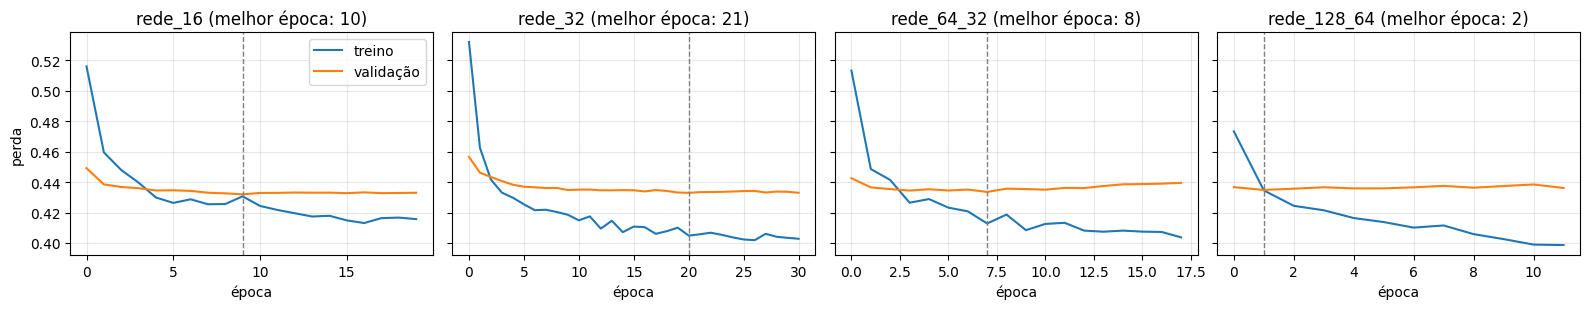

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, (nome, h) in zip(axs, historicos.items()):
    ax.plot(h.history["loss"], label="treino"); ax.plot(h.history["val_loss"], label="validação")
    melhor_ep = int(np.argmin(h.history["val_loss"]))
    ax.axvline(melhor_ep, ls="--", c="gray", lw=1)
    ax.set_title(f"{nome} (melhor época: {melhor_ep + 1})"); ax.set_xlabel("época"); ax.grid(alpha=0.3)
axs[0].set_ylabel("perda"); axs[0].legend(); plt.tight_layout(); plt.show()

In [ ]:
so_redes = experimentos[experimentos["modelo"].str.startswith("Keras")]
melhor_nome = so_redes.sort_values("auc", ascending=False).iloc[0]["modelo"].replace("Keras ", "")
melhor_rede = redes[melhor_nome]
auc_log = experimentos.loc[experimentos["modelo"].str.startswith("Regressão"), "auc"].iloc[0]
print(f"Melhor rede na validação: {melhor_nome} (AUC {so_redes['auc'].max():.3f}) | regressão logística: AUC {auc_log:.3f}")

Melhor rede na validação: rede_16 (AUC 0.833) | regressão logística: AUC 0.836


**Leitura das curvas e da tabela:**
- Nas quatro redes, a validação cai nas primeiras épocas e logo **para de cair** (nas duas maiores ela até sobe um pouco), enquanto o treino continua descendo: é o início da decoreba. A rede_128_64 chegou ao melhor ponto já na 2ª época. O **early stopping** esperou 10 épocas sem melhora, parou e devolveu a melhor versão (linha tracejada).
- **A maior rede não foi a melhor.** Com ~4 mil clientes de treino e poucas colunas, 128+64 neurônios é time demais para pouco jogo.
- A regressão logística ficou **praticamente empatada** com as redes. Isso é um resultado honesto e comum em tabelas pequenas: o baseline existe justamente para mostrar isso. Mantemos a rede como modelo principal porque é o que o desafio pede, e registramos o empate no model card.

## 3 · Abrir o cofre 🔓 (uma única vez)
A melhor rede foi escolhida **só** pela validação. Agora, pela primeira e única vez, medimos no teste — junto com o baseline, para comparar.

In [ ]:
X_teste_e = escala.transform(X_teste)
prob_rede = melhor_rede.predict(X_teste_e, verbose=0).ravel()
prob_log = logistica.predict_proba(X_teste_e)[:, 1]
res_rede, res_log = medir(y_teste, prob_rede), medir(y_teste, prob_log)
res_preg = medir(y_teste, np.zeros(len(y_teste)))

print(pd.DataFrame({"Preguiçoso": res_preg, "Regressão logística": res_log, f"Rede {melhor_nome}": res_rede}).T.to_string())
tn, fp, fn, tp = confusion_matrix(y_teste, (prob_rede >= 0.5).astype(int)).ravel()
print(f"\nNo teste: {tp} cancelamentos pegos, {fn} escaparam, {fp} alarmes falsos.")

                        auc  recall  precisao  acuracia
Preguiçoso           0.5000  0.0000    0.0000    0.7346
Regressão logística  0.8427  0.5588    0.6491    0.8027
Rede rede_16         0.8400  0.5374    0.6381    0.7963

No teste: 201 cancelamentos pegos, 173 escaparam, 114 alarmes falsos.


In [ ]:
# Frase de negócio: a equipe de retenção liga para os 20% de clientes com maior risco
n_lista = int(0.2 * len(y_teste))
ordem = np.argsort(-prob_rede)[:n_lista]
pegos = y_teste[ordem].sum(); total_cancel = y_teste.sum()
taxa_lista = pegos / n_lista; taxa_base = y_teste.mean()

print("💼 FRASE DE NEGÓCIO")
print(f"Ligando só para os 20% de clientes que a rede aponta como mais arriscados ({n_lista} de {len(y_teste)}), "
      f"a retenção alcança {pegos / total_cancel:.0%} de todos os que iam cancelar.")
print(f"Nessa lista, {taxa_lista:.0%} realmente cancelariam, contra {taxa_base:.0%} numa lista sorteada: "
      f"cada ligação vale cerca de {taxa_lista / taxa_base:.1f}x mais.")
print(f"Sem modelo, ligar para 20% sorteados alcançaria só ~20% dos cancelamentos.")

💼 FRASE DE NEGÓCIO
Ligando só para os 20% de clientes que a rede aponta como mais arriscados (281 de 1409), a retenção alcança 50% de todos os que iam cancelar.
Nessa lista, 66% realmente cancelariam, contra 27% numa lista sorteada: cada ligação vale cerca de 2.5x mais.
Sem modelo, ligar para 20% sorteados alcançaria só ~20% dos cancelamentos.


## 4 · Produto 📦 — modelo salvo + função de previsão + tela

In [ ]:
import joblib
melhor_rede.save("modelo_churn.keras")
cliente_tipico = X_bruto.loc[X_treino.index].mode().iloc[0]          # perfil mais comum do treino (valores padrão)
joblib.dump({"escala": escala, "colunas": COLUNAS, "cliente_tipico": cliente_tipico}, "preprocessamento.joblib")

rede_carregada = keras.models.load_model("modelo_churn.keras")
prep = joblib.load("preprocessamento.joblib")
print("Arquivos:", os.path.getsize("modelo_churn.keras") // 1024, "KB (rede) +",
      os.path.getsize("preprocessamento.joblib") // 1024, "KB (preparação)")
print("Mesmas previsões?", np.allclose(rede_carregada.predict(X_teste_e[:5], verbose=0),
                                       melhor_rede.predict(X_teste_e[:5], verbose=0)))

Arquivos: 30 KB (rede) + 5 KB (preparação)
Mesmas previsões? True


In [ ]:
CONTRATOS = {"Mês a mês": "Month-to-month", "1 ano": "One year", "2 anos": "Two year"}
INTERNET = {"Fibra": "Fiber optic", "DSL": "DSL", "Sem internet": "No"}
PAGAMENTOS = {"Boleto eletrônico": "Electronic check", "Boleto pelo correio": "Mailed check",
              "Débito automático": "Bank transfer (automatic)", "Cartão automático": "Credit card (automatic)"}

def prever_cancelamento(meses_cliente=3, mensalidade=80.0, contrato="Mês a mês", internet="Fibra",
                        pagamento="Boleto eletrônico", suporte_tecnico=False, seguranca_online=False,
                        fatura_digital=True, idoso=False):
    c = prep["cliente_tipico"].copy()
    c["tenure"], c["MonthlyCharges"] = meses_cliente, mensalidade
    c["TotalCharges"] = meses_cliente * mensalidade
    c["Contract"], c["InternetService"], c["PaymentMethod"] = CONTRATOS[contrato], INTERNET[internet], PAGAMENTOS[pagamento]
    sem_net = internet == "Sem internet"
    c["TechSupport"] = "No internet service" if sem_net else ("Yes" if suporte_tecnico else "No")
    c["OnlineSecurity"] = "No internet service" if sem_net else ("Yes" if seguranca_online else "No")
    c["PaperlessBilling"] = "Yes" if fatura_digital else "No"
    c["SeniorCitizen"] = int(idoso)
    entrada = prep["escala"].transform(preparar(pd.DataFrame([c]), prep["colunas"]))
    risco = float(rede_carregada.predict(entrada, verbose=0)[0, 0])
    nivel = "🔴 ALTO — ligar esta semana" if risco >= 0.5 else ("🟡 MÉDIO — acompanhar" if risco >= 0.25 else "🟢 BAIXO")
    print(f"📱 Risco de cancelamento: {risco:.0%}  →  {nivel}")
    return risco

prever_cancelamento(2, 95.0, "Mês a mês", "Fibra", "Boleto eletrônico", False, False, True, False)
prever_cancelamento(48, 60.0, "2 anos", "DSL", "Cartão automático", True, True, False, False);

📱 Risco de cancelamento: 69%  →  🔴 ALTO — ligar esta semana
📱 Risco de cancelamento: 2%  →  🟢 BAIXO


In [ ]:
from ipywidgets import interact
interact(prever_cancelamento, meses_cliente=(0, 72), mensalidade=(18.0, 120.0, 0.5),
         contrato=list(CONTRATOS), internet=list(INTERNET), pagamento=list(PAGAMENTOS));

interactive(children=(IntSlider(value=3, description='meses_cliente', max=72), FloatSlider(value=80.0, descrip…

👆 Aparecem controles deslizantes e caixas de seleção. Experimente: mantenha tudo igual e troque o contrato de **"Mês a mês"** para **"2 anos"**, ou aumente os **meses como cliente**, e veja o risco despencar.
📸 **Print desta tela** vai no README (`img/tela_produto.png`).

## 5 · Documentação — gerando o MODEL_CARD.md

In [ ]:
card = f'''# Model Card — RetémJá: risco de cancelamento de clientes

- **Uso pretendido:** gerar, toda semana, uma lista ordenada dos clientes com maior risco de cancelar, para o time de retenção oferecer ajuda/benefício antes da saída.
- **Não usar para:** negar atendimento, piorar condições, cobrar multa ou dificultar o cancelamento de quem tem risco alto; decidir preços diferentes por idade, gênero ou perfil familiar; avaliar ou punir atendentes pela "taxa de cancelamento" da carteira.
- **Dados:** {len(df)} clientes da base pública Telco Customer Churn (IBM/Kaggle), de uma operadora dos EUA; {df["cancelou"].mean():.1%} cancelaram. Divisão 60% treino / 20% validação / 20% teste, estratificada (seed {SEED}).
- **Modelo:** rede neural Keras {ARQUITETURAS[melhor_nome]} (ReLU + dropout 0.3, early stopping), escolhida entre 4 arquiteturas pela AUC de validação; comparada a uma regressão logística e a uma árvore de decisão.
- **Como medir se está bom:** AUC e recall (quantos cancelamentos ele pega), nunca só a acurácia (dizer "ninguém cancela" já acerta {1 - df["cancelou"].mean():.0%}). No teste: AUC {res_rede["auc"]:.3f}, recall {res_rede["recall"]:.0%}, acurácia {res_rede["acuracia"]:.0%} (regressão logística: AUC {res_log["auc"]:.3f}). Em negócio: ligando para os 20% mais arriscados, alcança {pegos / total_cancel:.0%} dos que iam cancelar. Em produção: comparar mês a mês o risco previsto com os cancelamentos reais.
- **Limitações:** dados antigos e de outro país (preços em dólar, planos que não existem no Brasil); não sabe por que o cliente cancela (atendimento ruim, concorrência, mudança); a regressão logística empata com a rede — vale reavaliar se a rede compensa; precisa ser re-treinado com dados reais da empresa e monitorado quando planos e preços mudarem.
'''
open("MODEL_CARD.md", "w", encoding="utf-8").write(card)
print(card)

# Model Card — RetémJá: risco de cancelamento de clientes

- **Uso pretendido:** gerar, toda semana, uma lista ordenada dos clientes com maior risco de cancelar, para o time de retenção oferecer ajuda/benefício antes da saída.
- **Não usar para:** negar atendimento, piorar condições, cobrar multa ou dificultar o cancelamento de quem tem risco alto; decidir preços diferentes por idade, gênero ou perfil familiar; avaliar ou punir atendentes pela "taxa de cancelamento" da carteira.
- **Dados:** 7043 clientes da base pública Telco Customer Churn (IBM/Kaggle), de uma operadora dos EUA; 26.5% cancelaram. Divisão 60% treino / 20% validação / 20% teste, estratificada (seed 42).
- **Modelo:** rede neural Keras [16] (ReLU + dropout 0.3, early stopping), escolhida entre 4 arquiteturas pela AUC de validação; comparada a uma regressão logística e a uma árvore de decisão.
- **Como medir se está bom:** AUC e recall (quantos cancelamentos ele pega), nunca só a acurácia (dizer "ninguém cancela" já acer